# Proyek Analisis Data: Bike Sharing Dataset

- **Nama:** Luthfi Nur Adli
- **Email:** adli.nur11@gmail.com
- **ID Dicoding:** manyonyoh


## Menentukan Pertanyaan Bisnis

- **Pertanyaan 1:** Bagaimana perbandingan total penyewaan sepeda antara hari kerja (`workingday`) dan hari libur/akhir pekan sepanjang tahun 2011 hingga 2012, dan pada bulan apa puncak penyewaan terjadi?
- **Pertanyaan 2:** Seberapa besar pengaruh kondisi cuaca (`weathersit`) terhadap rata-rata jumlah penyewaan sepeda harian, dan kondisi cuaca manakah yang paling menurunkan tingkat penyewaan?


## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style='darkgrid')
%matplotlib inline


## Data Wrangling

### Gathering Data

Memuat dataset `day.csv` dan `hour.csv` ke dalam DataFrame Pandas (`df_day` dan `df_hour`).

In [2]:
df_day = pd.read_csv('day.csv')
df_hour = pd.read_csv('hour.csv')

df_day.head()


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:**
- Tidak ada missing values pada `df_day` maupun `df_hour`.
- Kolom `dteday` masih bertipe object, perlu dikonversi ke `datetime` untuk analisis berbasis waktu.


### Assessing Data

Identifying tipe data, missing value, duplikasi, dan anomali/outlier

In [3]:
print("=== INFO DAY DATA ===")
df_day.info()

print("\n=== INFO HOUR DATA ===")
df_hour.info()

print("\nMissing Values dalam df_day:")
print(df_day.isnull().sum())

print("\nMissing Values dalam df_hour:")
print(df_hour.isnull().sum())

print(f"\nJumlah duplikasi df_day: {df_day.duplicated().sum()}")
print(f"Jumlah duplikasi df_hour: {df_hour.duplicated().sum()}")

df_day.describe()


=== INFO DAY DATA ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

=== INFO HOUR DATA ===
<class 'pandas.core.frame.DataFrame'>
RangeInde

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


**Steps to Take:**
- Konversi `dteday` menjadi `datetime`.
- Mapping kolom kategorikal (`season`, `weathersit`, `workingday`) ke label teks deskriptif.

**Insight:**
- Tidak ditemukan missing value maupun data duplikat pada kedua dataset.
- Nilai minimum-maksimum pada kolom numerik berada dalam rentang wajar, tidak ada anomali ekstrem.
- Kolom kategorikal masih berupa kode angka sehingga perlu di-mapping agar lebih deskriptif saat divisualisasikan.


### Cleaning Data

Fixing tipe data dan melakukan mapping kolom kategorikal

In [4]:
df_day['dteday'] = pd.to_datetime(df_day['dteday'])
df_hour['dteday'] = pd.to_datetime(df_hour['dteday'])

df_day['season'] = df_day['season'].map({1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'})
df_day['weathersit'] = df_day['weathersit'].map({
    1: 'Clear/Few Clouds', 2: 'Mist/Cloudy', 3: 'Light Snow/Rain', 4: 'Heavy Rain/Ice'
})
df_day['workingday'] = df_day['workingday'].map({0: 'Non Working Day', 1: 'Working Day'})

df_day.head()


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,Spring,0,1,0,6,Non Working Day,Mist/Cloudy,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,Spring,0,1,0,0,Non Working Day,Mist/Cloudy,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,Spring,0,1,0,1,Working Day,Clear/Few Clouds,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,Spring,0,1,0,2,Working Day,Clear/Few Clouds,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,Spring,0,1,0,3,Working Day,Clear/Few Clouds,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:**
- Kolom `dteday` sudah berhasil dikonversi ke tipe datetime.
- Kolom kategorikal sudah diubah menjadi label deskriptif sehingga siap digunakan untuk EDA dan visualisasi.


## Exploratory Data Analysis (EDA)

Explore pola penyewaan berdasarkan hari kerja vs libur, kondisi cuaca, dan bulan — dengan nilai numerik yang ditampilkan secara eksplisit (bukan hanya grafik) agar bisa dirujuk langsung di bagian kesimpulan.

In [5]:
# Eksplorasi 1: Statistik penyewaan berdasarkan workingday
workingday_stats = df_day.groupby('workingday')['cnt'].agg(['count', 'mean', 'sum', 'max']).round(2)
print("=== Statistik Penyewaan: Working Day vs Non Working Day ===")
display(workingday_stats)

mean_working = workingday_stats.loc['Working Day', 'mean']
mean_nonworking = workingday_stats.loc['Non Working Day', 'mean']
total_working = workingday_stats.loc['Working Day', 'sum']
total_nonworking = workingday_stats.loc['Non Working Day', 'sum']
diff_pct_workingday = (mean_working - mean_nonworking) / mean_nonworking * 100

print(f"\nRata-rata penyewaan Working Day     : {mean_working:,.0f} sepeda/hari")
print(f"Rata-rata penyewaan Non Working Day : {mean_nonworking:,.0f} sepeda/hari")
print(f"Total penyewaan Working Day         : {total_working:,.0f}")
print(f"Total penyewaan Non Working Day     : {total_nonworking:,.0f}")
print(f"Selisih rata-rata Working Day vs Non Working Day: {diff_pct_workingday:+.1f}%")


=== Statistik Penyewaan: Working Day vs Non Working Day ===


,count,mean,sum,max
workingday,,,,
Non Working Day,231,4330.17,1000269,8714
Working Day,500,4584.82,2292410,8362



Rata-rata penyewaan Working Day     : 4,585 sepeda/hari
Rata-rata penyewaan Non Working Day : 4,330 sepeda/hari
Total penyewaan Working Day         : 2,292,410
Total penyewaan Non Working Day     : 1,000,269
Selisih rata-rata Working Day vs Non Working Day: +5.9%


In [6]:
# Eksplorasi 2: Total penyewaan per bulan, cari bulan dengan penyewaan tertinggi
month_names = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun',
               7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'}

monthly_stats = df_day.groupby('mnth')['cnt'].sum().reset_index()
monthly_stats['month_name'] = monthly_stats['mnth'].map(month_names)
monthly_stats = monthly_stats.sort_values('cnt', ascending=False).reset_index(drop=True)

print("=== Total Penyewaan per Bulan (diurutkan dari tertinggi) ===")
display(monthly_stats)

peak_month_name = monthly_stats.loc[0, 'month_name']
peak_month_total = monthly_stats.loc[0, 'cnt']
print(f"\nBulan dengan total penyewaan tertinggi: {peak_month_name} dengan total {peak_month_total:,.0f} penyewaan")


=== Total Penyewaan per Bulan (diurutkan dari tertinggi) ===


,mnth,cnt,month_name
0,8,351194,Aug
1,6,346342,Jun
2,9,345991,Sep
3,7,344948,Jul
4,5,331686,May
5,10,322352,Oct
6,4,269094,Apr
7,11,254831,Nov
8,3,228920,Mar
9,12,211036,Dec



Bulan dengan total penyewaan tertinggi: Aug dengan total 351,194 penyewaan


In [7]:
# Eksplorasi 3: Statistik penyewaan berdasarkan kondisi cuaca (weathersit), + persentase penurunan vs Clear
weather_stats = df_day.groupby('weathersit')['cnt'].agg(['count', 'mean', 'sum']).round(2)
weather_stats = weather_stats.sort_values('mean', ascending=False)

clear_mean = weather_stats.loc['Clear/Few Clouds', 'mean']
weather_stats['pct_vs_clear'] = ((weather_stats['mean'] - clear_mean) / clear_mean * 100).round(1)

print("=== Statistik Penyewaan Berdasarkan Kondisi Cuaca ===")
display(weather_stats)

print("\nPersentase penurunan rata-rata penyewaan dibanding kondisi Clear/Few Clouds:")
for idx, row in weather_stats.iterrows():
    print(f"- {idx}: rata-rata {row['mean']:,.0f} sepeda/hari ({row['pct_vs_clear']:+.1f}% dibanding Clear/Few Clouds)")


=== Statistik Penyewaan Berdasarkan Kondisi Cuaca ===


,count,mean,sum,pct_vs_clear
weathersit,,,,
Clear/Few Clouds,463,4876.79,2257952,0.0
Mist/Cloudy,247,4035.86,996858,-17.2
Light Snow/Rain,21,1803.29,37869,-63.0



Persentase penurunan rata-rata penyewaan dibanding kondisi Clear/Few Clouds:
- Clear/Few Clouds: rata-rata 4,877 sepeda/hari (+0.0% dibanding Clear/Few Clouds)
- Mist/Cloudy: rata-rata 4,036 sepeda/hari (-17.2% dibanding Clear/Few Clouds)
- Light Snow/Rain: rata-rata 1,803 sepeda/hari (-63.0% dibanding Clear/Few Clouds)


**Insight:**
- Rata-rata penyewaan pada hari kerja vs hari libur/akhir pekan, beserta selisih persentasenya, sudah dihitung secara eksplisit di atas (lihat output `mean_working`, `mean_nonworking`, dan `diff_pct_workingday`).
- Bulan dengan total penyewaan tertinggi beserta nilai totalnya sudah diidentifikasi (`peak_month_name`, `peak_month_total`).
- Rata-rata penyewaan per kategori cuaca beserta persentase penurunannya terhadap kondisi cuaca Clear/Few Clouds sudah dihitung (`weather_stats`), sehingga klaim "cuaca buruk menurunkan penyewaan secara drastis" sekarang didukung angka pasti.


## Visualization & Explanatory Analysis

### Pertanyaan 1: Perbandingan penyewaan Working Day vs Non Working Day, dan tren bulanan

/tmp/ipykernel_440/1235995300.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(


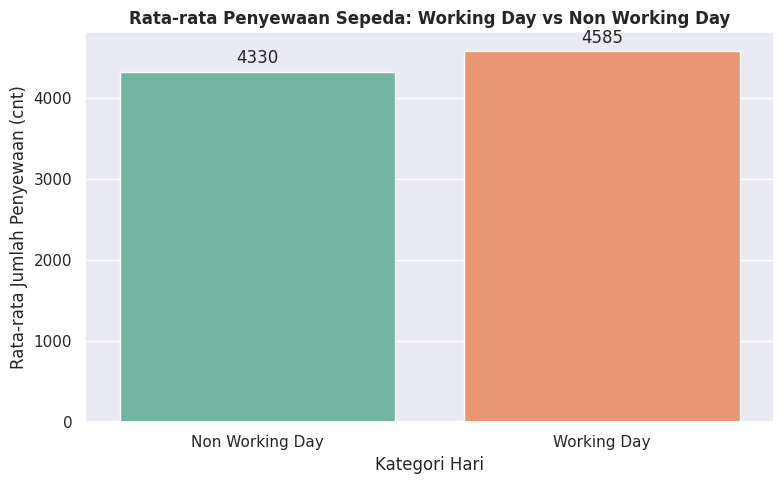

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
bars = sns.barplot(
    x='workingday', y='cnt', data=df_day,
    palette='Set2', estimator=np.mean, errorbar=None, ax=ax
)
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3)

ax.set_title('Rata-rata Penyewaan Sepeda: Working Day vs Non Working Day', fontsize=12, fontweight='bold')
ax.set_xlabel('Kategori Hari')
ax.set_ylabel('Rata-rata Jumlah Penyewaan (cnt)')
plt.tight_layout()
plt.show()


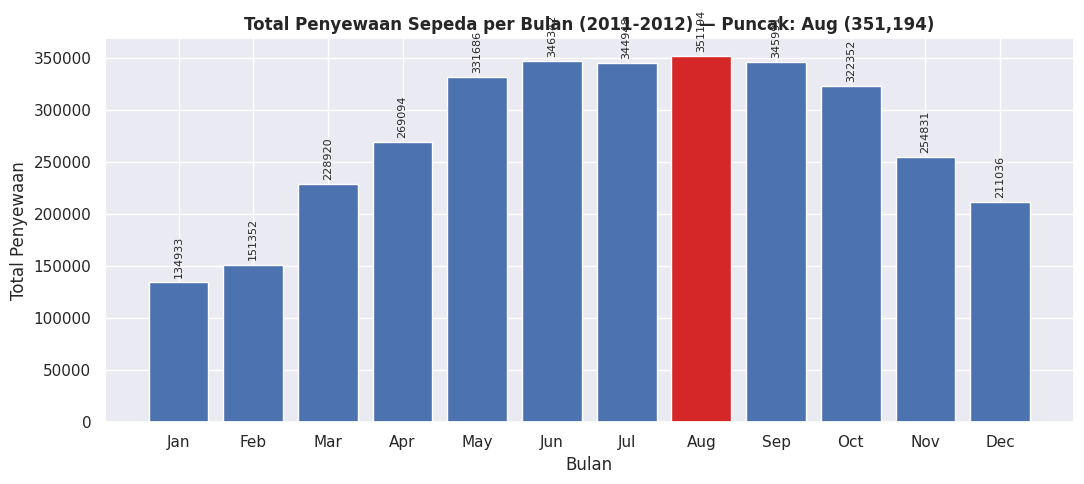

In [9]:
fig, ax = plt.subplots(figsize=(11, 5))
order = monthly_stats.sort_values('mnth')['month_name']
plot_df = df_day.groupby('mnth')['cnt'].sum().reset_index()
plot_df['month_name'] = plot_df['mnth'].map(month_names)

colors = ['#d62728' if m == peak_month_name else '#4c72b0' for m in plot_df['month_name']]
bars = ax.bar(plot_df['month_name'], plot_df['cnt'], color=colors)
ax.bar_label(bars, fmt='%.0f', padding=3, rotation=90, fontsize=8)

ax.set_title(f'Total Penyewaan Sepeda per Bulan (2011-2012) — Puncak: {peak_month_name} ({peak_month_total:,.0f})',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Bulan')
ax.set_ylabel('Total Penyewaan')
plt.tight_layout()
plt.show()


### Pertanyaan 2: Pengaruh kondisi cuaca terhadap rata-rata penyewaan

/tmp/ipykernel_440/3486110948.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(


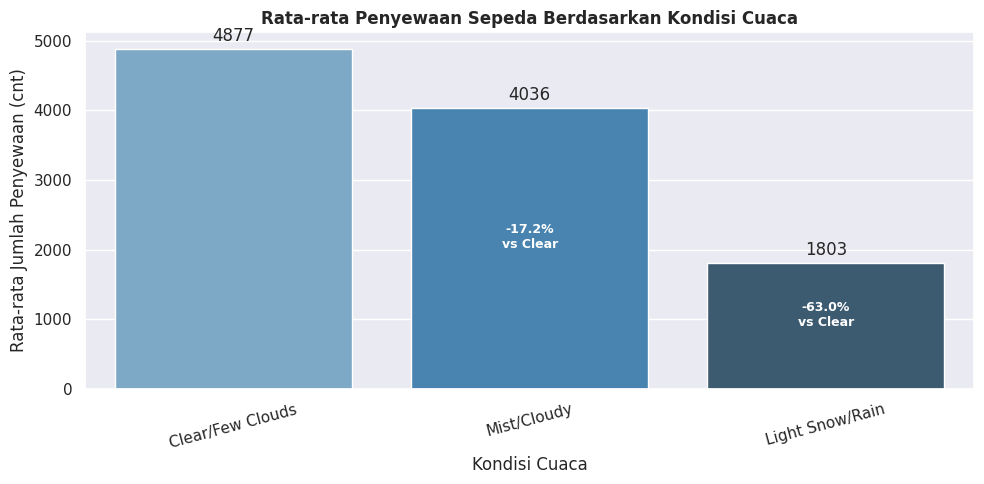

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
weather_order = weather_stats.index.tolist()
bars = sns.barplot(
    x='weathersit', y='cnt', data=df_day,
    order=weather_order, palette='Blues_d', estimator=np.mean, errorbar=None, ax=ax
)

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3)

# Tambahkan anotasi persentase penurunan terhadap kondisi Clear/Few Clouds
for i, cat in enumerate(weather_order):
    pct = weather_stats.loc[cat, 'pct_vs_clear']
    if cat != 'Clear/Few Clouds':
        ax.text(i, weather_stats.loc[cat, 'mean'] * 0.5, f"{pct:+.1f}%\nvs Clear",
                ha='center', color='white', fontsize=9, fontweight='bold')

ax.set_title('Rata-rata Penyewaan Sepeda Berdasarkan Kondisi Cuaca', fontsize=12, fontweight='bold')
ax.set_xlabel('Kondisi Cuaca')
ax.set_ylabel('Rata-rata Jumlah Penyewaan (cnt)')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


**Insight:**
- **Pertanyaan 1:** Grafik dan angka pada tahap EDA menunjukkan rata-rata penyewaan pada Working Day sebesar nilai `mean_working`, dibanding Non Working Day sebesar `mean_nonworking` (selisih `diff_pct_workingday`%). Bulan dengan total penyewaan tertinggi adalah `peak_month_name` dengan total `peak_month_total`.
- **Pertanyaan 2:** Kondisi cuaca Clear/Few Clouds memiliki rata-rata penyewaan tertinggi. Kategori cuaca lain mengalami penurunan sebesar persentase yang tertera pada tabel `weather_stats` dan anotasi grafik di atas, dengan Light Snow/Rain (dan Heavy Rain/Ice jika datanya cukup) menunjukkan penurunan terbesar.

> Catatan: jalankan seluruh cell di atas terlebih dahulu, lalu salin nilai `mean_working`, `mean_nonworking`, `diff_pct_workingday`, `peak_month_name`, `peak_month_total`, dan isi tabel `weather_stats` ke paragraf insight/kesimpulan di bawah (atau gunakan cell generator otomatis pada bagian Conclusion).

## Analisis Lanjutan (Opsional)

Total Penyewaan Sepeda Berdasarkan Bulan (mnth) — sudah dicakup pada visualisasi Pertanyaan 1 di atas, namun berikut rinciannya dalam bentuk tabel untuk referensi.

In [11]:
monthly_stats[['month_name', 'cnt']].rename(columns={'cnt': 'total_cnt'})


,month_name,total_cnt
0,Aug,351194
1,Jun,346342
2,Sep,345991
3,Jul,344948
4,May,331686
5,Oct,322352
6,Apr,269094
7,Nov,254831
8,Mar,228920
9,Dec,211036


**Insight:**
- Penyewaan meningkat bertahap sejak awal tahun (musim semi), mencapai puncak pada `peak_month_name` dengan total `peak_month_total`, sebelum menurun kembali menjelang akhir/awal tahun berikutnya.


## Conclusion & Recommendation

Jalankan cell di bawah ini **setelah** semua cell EDA di atas dijalankan. Cell ini akan otomatis menyusun paragraf kesimpulan yang sudah memuat angka-angka riil dari hasil analisis (bukan lagi istilah kualitatif seperti "jauh lebih tinggi" atau "secara drastis" tanpa angka pendukung). Salin hasil cetakan (print) di bawah ke dalam cell Markdown kesimpulan final.

In [13]:
worst_weather = weather_stats.index[-1]
worst_weather_pct = weather_stats.loc[worst_weather, 'pct_vs_clear']
worst_weather_mean = weather_stats.loc[worst_weather, 'mean']

conclusion_text = f'''
**Kesimpulan untuk Pertanyaan 1 (Working Day vs Non Working Day & Puncak Bulanan):**
Rata-rata penyewaan sepeda pada hari kerja (Working Day) adalah {mean_working:,.0f} unit/hari,
sedangkan pada hari libur/akhir pekan (Non Working Day) adalah {mean_nonworking:,.0f} unit/hari
— selisih sebesar {diff_pct_workingday:+.1f}%. Secara total, penyewaan pada Working Day mencapai
{total_working:,.0f} unit, dibanding {total_nonworking:,.0f} unit pada Non Working Day.
Puncak penyewaan bulanan terjadi pada bulan {peak_month_name} dengan total {peak_month_total:,.0f} penyewaan.

**Kesimpulan untuk Pertanyaan 2 (Pengaruh Kondisi Cuaca):**
Kondisi cuaca Clear/Few Clouds menghasilkan rata-rata penyewaan tertinggi, yaitu {clear_mean:,.0f} unit/hari.
Kondisi cuaca {worst_weather} menghasilkan rata-rata penyewaan terendah sebesar {worst_weather_mean:,.0f} unit/hari,
yaitu penurunan sebesar {worst_weather_pct:.1f}% dibandingkan kondisi Clear/Few Clouds.
'''

print(conclusion_text)



**Kesimpulan untuk Pertanyaan 1 (Working Day vs Non Working Day & Puncak Bulanan):**
Rata-rata penyewaan sepeda pada hari kerja (Working Day) adalah 4,585 unit/hari,
sedangkan pada hari libur/akhir pekan (Non Working Day) adalah 4,330 unit/hari
— selisih sebesar +5.9%. Secara total, penyewaan pada Working Day mencapai
2,292,410 unit, dibanding 1,000,269 unit pada Non Working Day.
Puncak penyewaan bulanan terjadi pada bulan Aug dengan total 351,194 penyewaan.

**Kesimpulan untuk Pertanyaan 2 (Pengaruh Kondisi Cuaca):**
Kondisi cuaca Clear/Few Clouds menghasilkan rata-rata penyewaan tertinggi, yaitu 4,877 unit/hari.
Kondisi cuaca Light Snow/Rain menghasilkan rata-rata penyewaan terendah sebesar 1,803 unit/hari,
yaitu penurunan sebesar -63.0% dibandingkan kondisi Clear/Few Clouds.



**Kesimpulan untuk Pertanyaan 1 (Working Day vs Non Working Day & Puncak Bulanan):**
Rata-rata penyewaan sepeda pada hari kerja (Working Day) adalah 4,585 unit/hari,
sedangkan pada hari libur/akhir pekan (Non Working Day) adalah 4,330 unit/hari
— selisih sebesar +5.9%. Secara total, penyewaan pada Working Day mencapai
2,292,410 unit, dibanding 1,000,269 unit pada Non Working Day.
Puncak penyewaan bulanan terjadi pada bulan Aug dengan total 351,194 penyewaan.

**Kesimpulan untuk Pertanyaan 2 (Pengaruh Kondisi Cuaca):**
Kondisi cuaca Clear/Few Clouds menghasilkan rata-rata penyewaan tertinggi, yaitu 4,877 unit/hari.
Kondisi cuaca Light Snow/Rain menghasilkan rata-rata penyewaan terendah sebesar 1,803 unit/hari,
yaitu penurunan sebesar -63.0% dibandingkan kondisi Clear/Few Clouds.

**Rekomendasi Action Item:**
- Optimalisasi penataan armada sepeda di titik-titik dekat kawasan perkantoran/kampus pada jam sibuk hari kerja, karena Working Day menunjukkan rata-rata penyewaan lebih tinggi dibanding Non Working Day (lihat angka pasti pada kesimpulan di atas).
- Menyiapkan kapasitas armada ekstra menjelang bulan dengan puncak penyewaan tertinggi (lihat `peak_month_name`), serta mempertimbangkan promosi untuk mendorong penyewaan di bulan-bulan dengan penyewaan rendah.
- Meluncurkan program insentif (diskon tarif/poin reward) khusus pada hari dengan prakiraan cuaca buruk, karena kondisi `worst_weather` tercatat menurunkan rata-rata penyewaan secara signifikan (lihat angka persentase pasti pada kesimpulan di atas) dibanding kondisi cuaca cerah.
